### Javier Carballal Morgade
### Claudia Reyero Bardelás

# Grover's algorithm

Grover's problem asks us to find a marked binary string $x^*$ using access to a black-box function

$$f(x)=\begin{cases}1 & \text{if }x=x^*,\\0 & \text{otherwise.}\end{cases}$$

This problem is an unstructured search, meaning that there is no heuristic that can be applied to find the target state faster than trial and error. A classical search needs $O(N)$ oracle queries in the worst case for $N=2^n$ candidates. Grover's algorithm uses amplitude amplification to find the marked state with only $O(\sqrt{N})$ queries.

In [156]:
from math import asin, pi, sqrt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

## Choosing the target state

This is the state that the quantum circuit must discover. We start with the three-qubit target $|101\rangle$, so the search space contains $N=2^3=8$ states.

In [157]:
target_state = "101"
n = len(target_state)
N = 2**n

print(f"Target state: |{target_state}>")
print(f"Search-space size: {N}")

Target state: |101>
Search-space size: 8


## The oracle

The oracle evaluates whether the input $x$ is the target state. Its function is

$$f(x)=\begin{cases}1 & \text{if }x=x^*,\\0 & \text{otherwise.}\end{cases}$$

Thus, $f(x)$ must be 1 only when the input qubits encode the chosen target state, and 0 for every other input. The reversible oracle writes this result into an auxiliary output qubit:

$$U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle.$$

The way to implement this is a multi-controlled NOT that flips the output qubit when all its input controls are 1. To use it for any target other than $|11\ldots1\rangle$, we first apply an $X$ gate to each input qubit whose target bit is 0. This temporarily maps the target to $|11\ldots1\rangle$, allowing the multi-controlled NOT to produce $f(x)=1$ only for that input. The initial $X$ gates are then applied again to undo the mapping.

Qiskit numbers qubits from the least-significant bit, while strings are written most-significant bit first. We therefore reverse the target string when associating its bits with qubits.

Oracle that marks |101>:


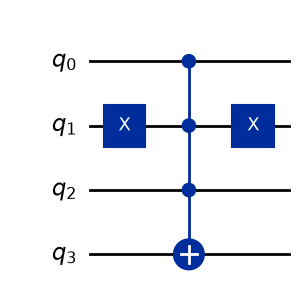

In [158]:
def make_oracle(target_state):
    n = len(target_state)
    oracle = QuantumCircuit(n + 1, name="U_f")
    zero_qubits = [
        qubit for qubit, bit in enumerate(reversed(target_state)) if bit == "0"
    ]

    if zero_qubits:
        oracle.x(zero_qubits)
    oracle.mcx(list(range(n)), n)
    if zero_qubits:
        oracle.x(zero_qubits)

    return oracle.to_gate(label=f"U_{target_state}")


oracle_gate = make_oracle(target_state)
print(f"Oracle that marks |{target_state}>:")
display(oracle_gate.definition.draw("mpl"))

## The diffusion operator

The diffuser performs inversion about the mean on the input amplitudes:

$$D=2|s\rangle\langle s|-I=H^{\otimes n}(2|0\ldots0\rangle\langle0\ldots0|-I)H^{\otimes n}.$$

In practice, it is implemented by applying Hadamard gates, making a refection around $|0\ldots0\rangle$ and applying Hadamard gates again. To do the inversion, we map $|0\ldots0\rangle$ to $|1\ldots1\rangle$, apply a multi-controlled Z, and undo the mapping.

Diffusion operator:


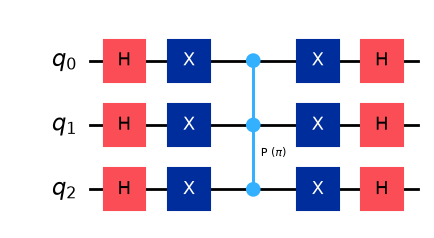

In [159]:
def make_diffuser(n):

    diffuser = QuantumCircuit(n, name="D")

    diffuser.h(range(n))
    diffuser.x(range(n))
    diffuser.mcp(pi, list(range(n - 1)), n - 1) # Controlled-Z gate
    diffuser.x(range(n))
    diffuser.h(range(n))

    return diffuser.to_gate(label="D")


diffuser_gate = make_diffuser(n)
print("Diffusion operator:")
display(diffuser_gate.definition.draw("mpl"))

## The circuit

### Initial state

The initial state for this algorithm contains a uniform superposition of every possible $x$ for the input qubits and the $|{-}\rangle$ state for the ancilla qubit, preparing it for phase kickback.

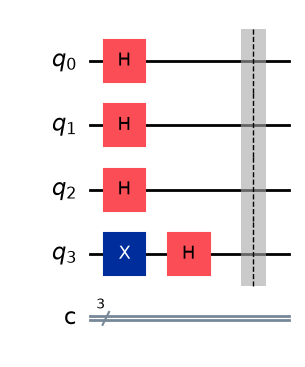

In [160]:
qc = QuantumCircuit(n + 1, n)  # n input qubits, one ancilla, and n classical bits

qc.h(range(n))  # Initialize input qubits in superposition
qc.x(n)
qc.h(n)
qc.barrier()

display(qc.draw("mpl"))

### Calculating the necessary iterations


In [161]:
theta = asin(1 / sqrt(N))
iterations = max(1, round(pi / (4 * theta) - 0.5))

print("Number of Grover iterations:", iterations)

Number of Grover iterations: 2


### Append the iterations of Oracle and Diffusion

The Grover algorithm works by applying iterations of the Oracle and Diffusion operators.

- The oracle flips only the phase of the target state in the input superposition. The ancilla remains in $|{-}\rangle$ and is not measured or used from this point.

- Then the diffuser reflects the resulting state about $|s\rangle$. The effect of this operation brings the state closer to the target.

In order to maximize the probability of measuring the target state, we repeat this sequence for as many iterations as calculated before.

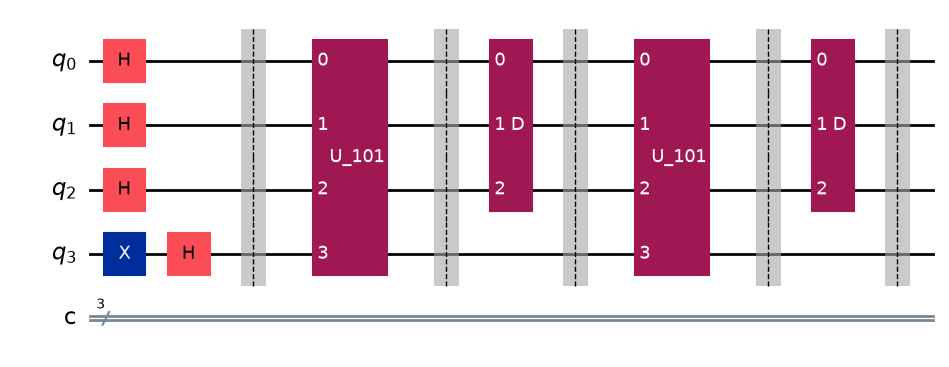

In [162]:
for _ in range(iterations):
    qc.append(oracle_gate, range(n + 1))
    qc.barrier()
    qc.append(diffuser_gate, range(n))
    qc.barrier()

display(qc.draw("mpl"))

### Measurement

Only the input register is measured.

Final circuit:


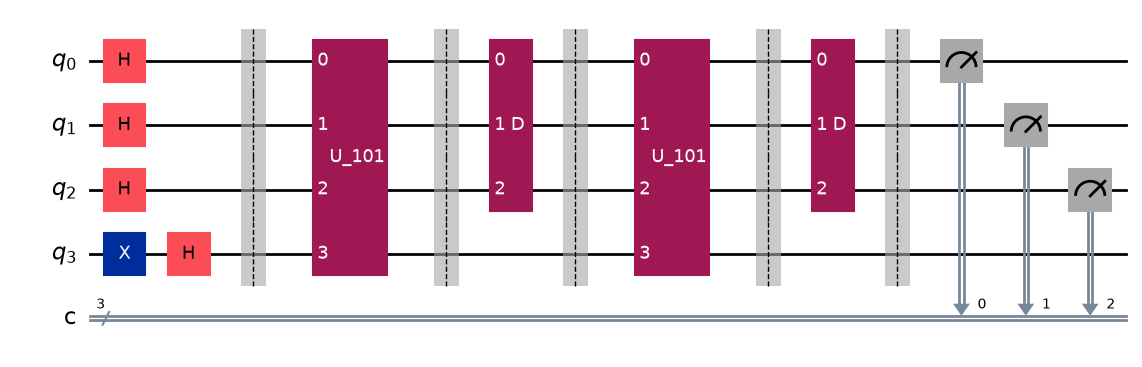

Circuit with the oracle and diffuser decomposed:


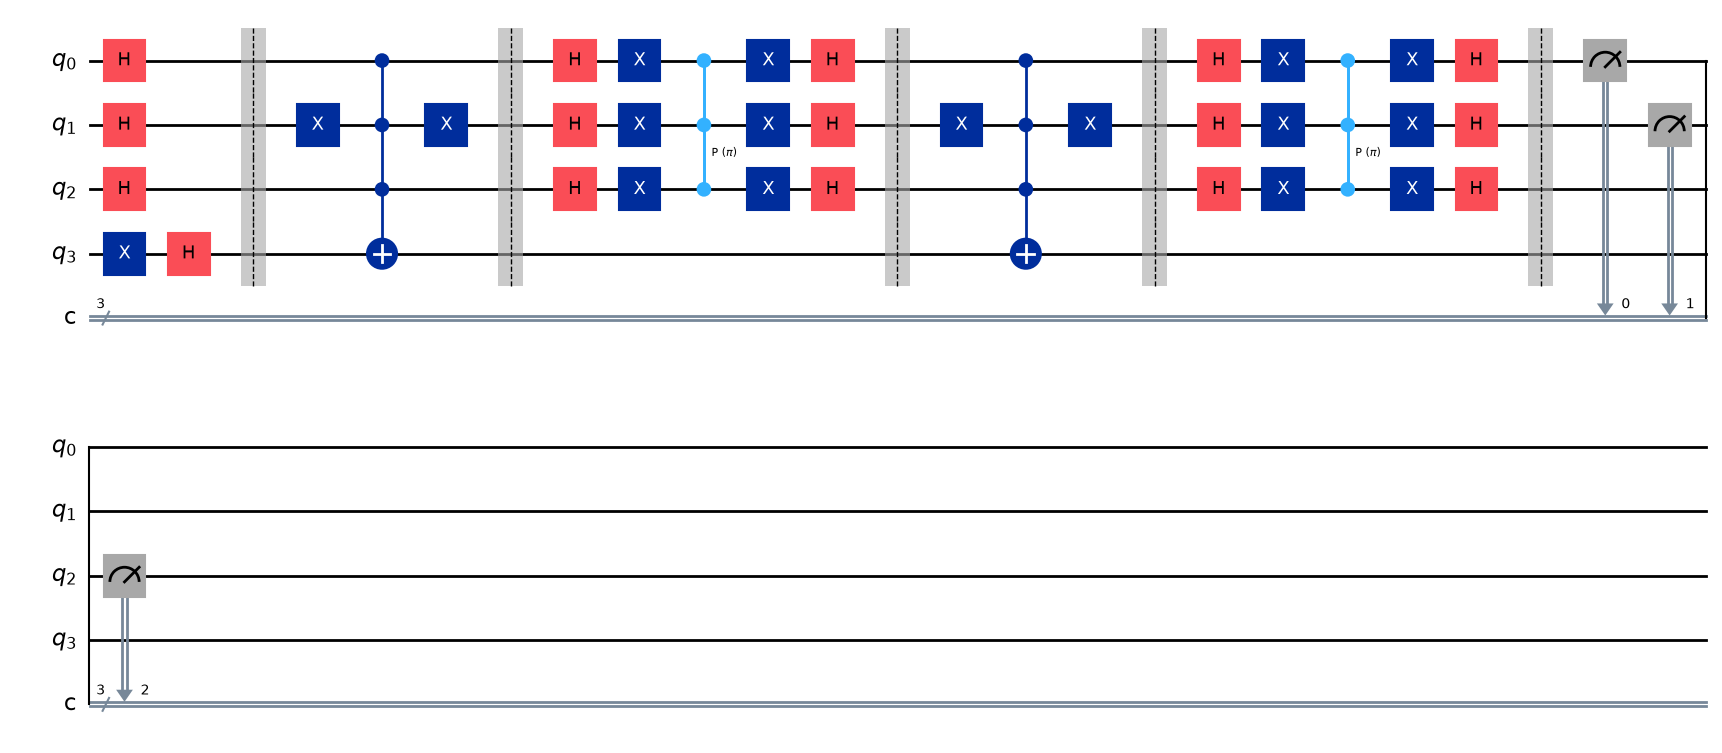

In [163]:
qc.measure(range(n), range(n))

print("Final circuit:")
display(qc.draw("mpl"))

print("Circuit with the oracle and diffuser decomposed:")
display(qc.decompose(gates_to_decompose=["U_f", "D"]).draw("mpl"))

## Run the circuit

Grover's result is probabilistic: for $N=8$ and two iterations, the theoretical success probability is about $94.5\%$. The target state should dominate the histogram, but a small number of other outcomes is expected.

Measurement results: {'110': 4, '010': 6, '000': 9, '001': 6, '111': 10, '011': 7, '100': 12, '101': 970}


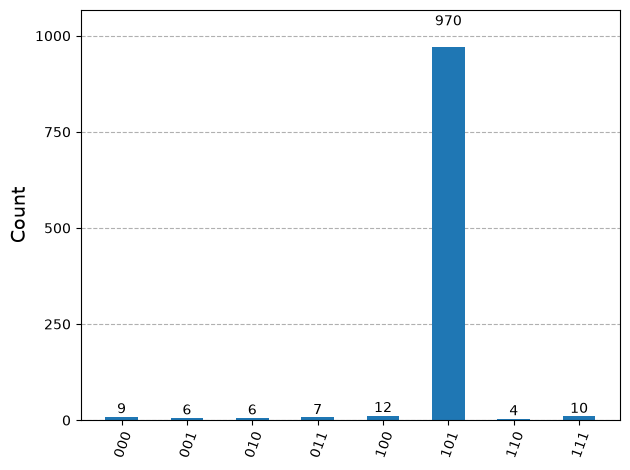

In [164]:
simulator = AerSimulator()
compiled_circuit = transpile(qc, simulator)
result = simulator.run(compiled_circuit, shots=1024).result()
counts = result.get_counts()
most_frequent = max(counts, key=counts.get)

print("Measurement results:", counts)
plot_histogram(counts)

## Trying other target states

These oracles encode functions with different target states. The code underneath is a compact version of the algorithm to test them out independently.

Oracle that marks |0>:


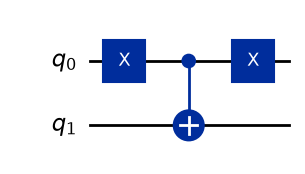

Oracle that marks |01>:


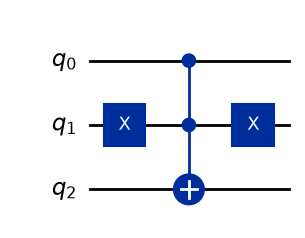

Oracle that marks |001>:


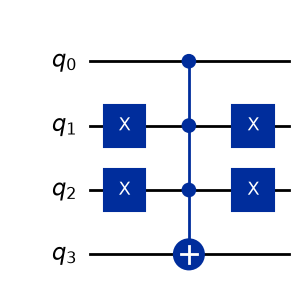

Oracle that marks |100>:


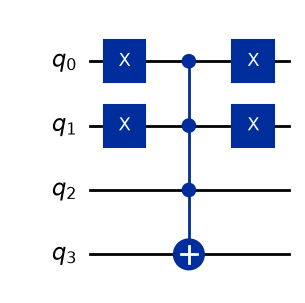

Oracle that marks |111>:


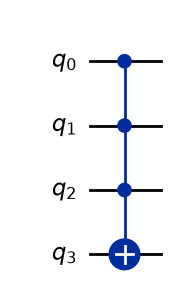

Oracle that marks |101001>:


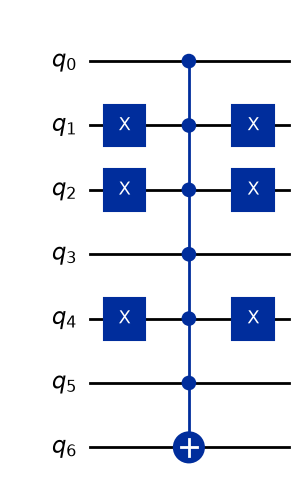

Oracle that marks |111111>:


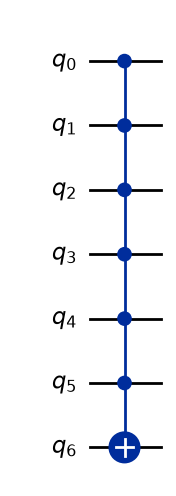

In [165]:
test_targets = ["0", "01", "001", "100", "111", "101001", "111111"]

for target in test_targets:
    print(f"Oracle that marks |{target}>:")
    display(make_oracle(target).definition.draw("mpl"))

In [166]:
def grover_circuit(target_state):
    n = len(target_state)
    circuit = QuantumCircuit(n + 1, n)

    # Initial state
    circuit.h(range(n))
    circuit.x(n)
    circuit.h(n)

    oracle = make_oracle(target_state)
    diffuser = make_diffuser(n)

    # Calculate the number of iterations
    theta = asin(1 / sqrt(2**n))
    iterations = max(1, round(pi / (4 * theta) - 0.5))

    for _ in range(iterations):
        circuit.append(oracle, range(n + 1))
        circuit.append(diffuser, range(n))

    circuit.measure(range(n), range(n))
    return circuit


for target in test_targets:
    qc = grover_circuit(target)
    compiled = transpile(qc, simulator)
    counts = simulator.run(compiled, shots=1024).result().get_counts()
    found = max(counts, key=counts.get)
    print(f"target = {target} \t most frequent = {found} \t correct = {found == target} \t target counts = {counts.get(target, 0)}")
    assert found == target

target = 0 	 most frequent = 0 	 correct = True 	 target counts = 521
target = 01 	 most frequent = 01 	 correct = True 	 target counts = 1024
target = 001 	 most frequent = 001 	 correct = True 	 target counts = 977
target = 100 	 most frequent = 100 	 correct = True 	 target counts = 972
target = 111 	 most frequent = 111 	 correct = True 	 target counts = 966
target = 101001 	 most frequent = 101001 	 correct = True 	 target counts = 1024
target = 111111 	 most frequent = 111111 	 correct = True 	 target counts = 1018
